# Fair-value model: results

This notebook visualises the output of `src/model/fair_value.py`.

**Question:** what should a Madrid flat rent for, and which listings sit well above or below that estimate?

**Method (short):** three models predict monthly `Rent` (€) on a log scale, using 5-fold out-of-fold predictions so every listing is scored by a model that never saw it. A split-conformal interval is calibrated on held-out flats, and its width varies by flat: a scale model learns each flat's typical error from its features. Coverage is checked on a separate test set (target 90%, achieved 92.9%). Each listing's *score* is its log gap, `log(actual ÷ predicted)`, divided by the interval half-width. A flat is *overpriced* when its rent is above the interval (score above 1), *below typical* when below it (score below −1), and *fair* otherwise. The score ranks flags; it is not a probability.

**Caveat:** labels are relative to comparable listings in this dataset, not to true market value. The 3-way labels come from the same model, so their accuracy can't be judged on their own. The honest yardstick is the euro error of the out-of-fold predictions.

In [1]:
import importlib.util, sys

REQUIRED = ["numpy", "pandas", "sklearn", "matplotlib", "IPython"]
missing = [m for m in REQUIRED if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError(
        f"Kernel {sys.executable} is missing: {', '.join(missing)}. "
        f"Install with: {sys.executable} -m pip install {' '.join(missing)} "
        "then Restart the kernel."
    )

from pathlib import Path

def find_repo_root(start: Path) -> Path:
    # Walk up from the notebook's working directory until the folder holding src/data/ is found.
    for candidate in [start, *start.parents]:
        if (candidate / "src" / "data" / "data_acquire.py").exists():
            return candidate
    raise RuntimeError(
        f"Could not find the MLProjectBAM repo above {start}. "
        "Open the notebook from inside the repo (e.g. src/model/) and restart the kernel."
    )

REPO = find_repo_root(Path.cwd().resolve())
sys.path.insert(0, str(REPO))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.inspection import permutation_importance

from src.data.data_acquire import load_df
from src.data.preprocess import prepare_xy, NUMERIC_COLS, CATEGORICAL_COLS, TARGET
from src.model.fair_value import make_models, euro_metrics, SEED, N_FOLDS, OUTPUT

warnings.filterwarnings("ignore")

# ---- Look and feel (Okabe-Ito-leaning, colourblind-safe, recessive grid) ----
from src.model.style import PAL, LABEL_COL, LABEL_ORDER, MODEL_COL, EUR, apply_style
apply_style()
PCT = mtick.FuncFormatter(lambda v, _: f"{v:+.0f}%")
print("Repo root:", REPO)

Repo root: /Users/philipalexopoulos/MLProjectBAM


## 1. Load the data and the saved labels

In [2]:
df = load_df()
X, y = prepare_xy(df)
actual = y.to_numpy()
y_log = np.log(actual)
cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

labels = pd.read_csv(OUTPUT)
assert len(labels) == len(df), "label file and dataset differ in length"
assert (labels["Id"].to_numpy() == df["Id"].to_numpy()).all(), "row order mismatch"

print(f"Listings: {len(df):,}   target: {TARGET} (€ per month)")
print(f"Price range: €{actual.min():,.0f} to €{actual.max():,.0f}   median €{np.median(actual):,.0f}")
labels.head()

Listings: 1,840   target: Rent (€ per month)
Price range: €450 to €3,500   median €1,300


,Id,actual_eur,predicted_eur,gap_pct,interval_low_eur,interval_high_eur,score,label,halfwidth_log,sigma_log
0,1,1300.0,1010.28,28.68,806.31,1265.85,1.118,overpriced,0.2255,0.0629
1,2,3000.0,2792.30,7.44,2116.18,3684.44,0.259,fair,0.2773,0.0774
2,3,1300.0,1070.10,21.48,854.30,1340.41,0.864,fair,0.2252,0.0628
3,4,1600.0,1604.94,-0.31,1326.07,1942.45,-0.016,fair,0.1909,0.0533
4,5,800.0,850.64,-5.95,659.19,1097.70,-0.241,fair,0.2550,0.0711


## 2. Which model predicts best?

In [3]:
# Re-run the same out-of-fold predictions as fair_value.py so every model is available here.
oof = {}
results = {}
for name, model in make_models().items():
    oof_log = cross_val_predict(model, X, y_log, cv=cv)
    oof[name] = np.exp(oof_log)
    results[name] = euro_metrics(actual, oof[name])

report = pd.DataFrame(results).T
report.index.name = "model"
display_cols = {"MAE_eur": "MAE (€)", "MedAE_eur": "Median AE (€)", "MAPE_pct": "MAPE (%)", "R2_log": "R² (log price)"}
table = report.rename(columns=display_cols).round(2)
print("Out-of-fold error by model (lower error is better)")
table

Out-of-fold error by model (lower error is better)


,MAE (€),Median AE (€),MAPE (%),R² (log price)
model,,,,
baseline_median,604.81,450.00,39.99,-0.01
ridge,295.80,180.34,18.13,0.76
gradient_boosting,260.01,167.77,16.75,0.79


**Reading this:** The gradient-boosting model cuts the typical euro miss from €605 (median baseline) to €260, about 57% lower. It explains 79% of the variance in log rent, against 76% for ridge (MAE €296). The median absolute error is €168, roughly 13% of the median rent of €1,300.

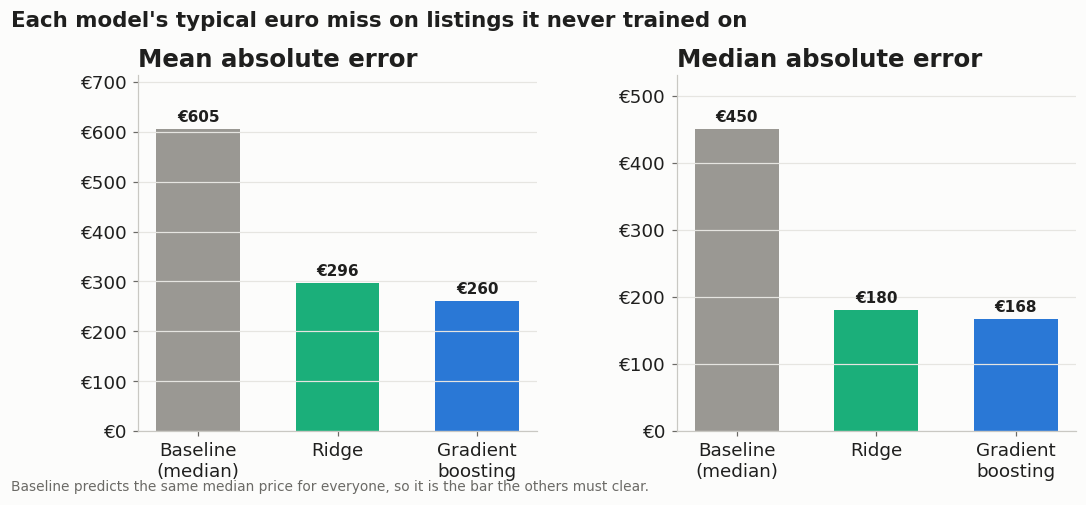

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"wspace": 0.35})
names = list(report.index)
colors = [MODEL_COL[n] for n in names]
pretty = {"baseline_median": "Baseline\n(median)", "ridge": "Ridge", "gradient_boosting": "Gradient\nboosting"}
xl = [pretty[n] for n in names]

for ax, metric, title in zip(axes, ["MAE_eur", "MedAE_eur"], ["Mean absolute error", "Median absolute error"]):
    vals = report[metric].to_numpy()
    bars = ax.bar(xl, vals, color=colors, width=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + vals.max() * 0.015, f"€{v:,.0f}",
                ha="center", va="bottom", fontsize=10, color=PAL["ink"], fontweight="bold")
    ax.set_title(title, loc="left")
    ax.yaxis.set_major_formatter(EUR)
    ax.set_ylim(0, vals.max() * 1.18)

fig.suptitle("Each model's typical euro miss on listings it never trained on", x=0.02, ha="left",
             fontsize=14, fontweight="bold", color=PAL["ink"], y=1.02)
fig.text(0.02, -0.02, "Baseline predicts the same median price for everyone, so it is the bar the others must clear.",
         fontsize=9, color=PAL["muted"])
plt.show()

## 3. Actual vs predicted price

Best model by MAE: gradient_boosting


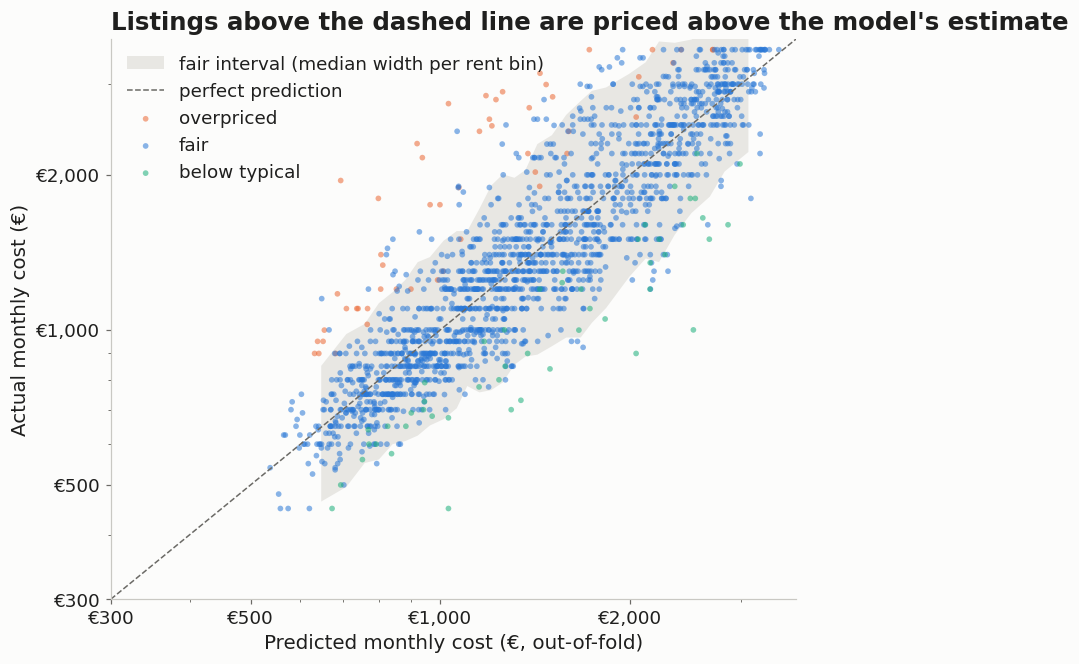

In [5]:
best = min((n for n in results if n != "baseline_median"), key=lambda n: results[n]["MAE_eur"])
pred = oof[best]
gap = np.log(actual / pred)  # log gap: +x and -x are symmetric
gap_pct = (np.exp(gap) - 1) * 100  # the same gap, shown as a % of predicted rent
print(f"Best model by MAE: {best}")

fig, ax = plt.subplots(figsize=(7.5, 6.2))
lo, hi = 300, max(actual.max(), pred.max()) * 1.05
# Smooth envelope: median interval within 30 bins of predicted rent (per-flat intervals are plotted as the flags).
low = labels["interval_low_eur"].to_numpy(); high = labels["interval_high_eur"].to_numpy()
edges = np.quantile(pred, np.linspace(0, 1, 31))
which = np.clip(np.searchsorted(edges, pred, side="right") - 1, 0, 29)
xs, lows, highs = [], [], []
for k in range(30):
    m = which == k
    if m.sum() == 0: continue
    xs.append(np.median(pred[m])); lows.append(np.median(low[m])); highs.append(np.median(high[m]))
ax_fill = (np.array(xs), np.array(lows), np.array(highs))
ax.fill_between(ax_fill[0], ax_fill[1], ax_fill[2], color=PAL["grid"], alpha=0.9, lw=0,
                label="fair interval (median width per rent bin)")
ax.plot([lo, hi], [lo, hi], color=PAL["muted"], lw=1, ls="--", label="perfect prediction")

for lab in LABEL_ORDER:
    m = labels["label"].to_numpy() == lab
    ax.scatter(pred[m], actual[m], s=14, alpha=0.55, color=LABEL_COL[lab], edgecolor="none", label=lab.replace("_", " "))

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ticks = [t for t in [300, 500, 1000, 2000, 4000, 8000, 16000] if lo <= t <= hi]
ax.set_xticks(ticks); ax.set_yticks(ticks)
ax.xaxis.set_major_formatter(EUR); ax.yaxis.set_major_formatter(EUR)
ax.xaxis.set_minor_formatter(mtick.NullFormatter()); ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_xlabel("Predicted monthly cost (€, out-of-fold)")
ax.set_ylabel("Actual monthly cost (€)")
ax.set_title("Listings above the dashed line are priced above the model's estimate", loc="left")
ax.grid(False)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Reading this:** The shaded fan is each flat's own 90% interval. It is narrow for cheap flats (about ±€270 in the cheapest quartile) and wide for expensive ones (about ±€1,000 in the most expensive). Points outside the fan are the flags. Because the fan is drawn in each flat's own width, it stays honest across the full rent range.

## 4. How far off are listings?

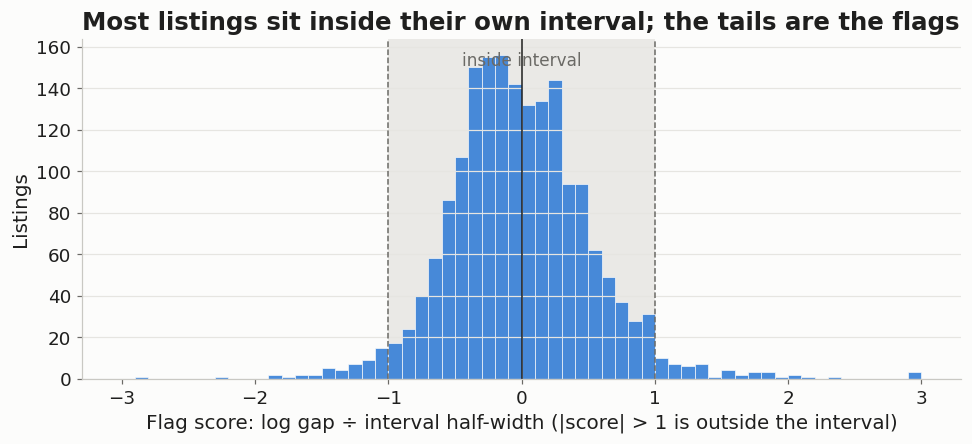

Median score: -0.05   share labelled fair: 94.6%
Median gap: -1.8%


In [6]:
clip = 3
fig, ax = plt.subplots(figsize=(9, 4.2))
score = labels["score"].to_numpy()
bins = np.linspace(-clip, clip, 61)
ax.hist(np.clip(score, -clip, clip), bins=bins, color=PAL["primary"], alpha=0.85, edgecolor=PAL["surface"], lw=0.5)
ax.axvspan(-1, 1, color=PAL["grid"], alpha=0.8, lw=0, zorder=0)
ax.axvline(0, color=PAL["ink"], lw=1)
ax.axvline(-1, color=PAL["muted"], lw=1, ls="--")
ax.axvline(1, color=PAL["muted"], lw=1, ls="--")
ax.set_xlabel("Flag score: log gap ÷ interval half-width (|score| > 1 is outside the interval)")
ax.set_ylabel("Listings")
ax.set_title("Most listings sit inside their own interval; the tails are the flags", loc="left")
ax.text(0, ax.get_ylim()[1] * 0.92, "inside interval", ha="center", color=PAL["muted"], fontsize=11)
plt.tight_layout()
plt.show()

print(f"Median score: {np.median(score):+.2f}   share labelled fair: {(labels['label'] == 'fair').mean()*100:.1f}%")
print(f"Median gap: {np.median(gap_pct):+.1f}%")


**Reading this:** The gap is centred near zero (median −1.8%), so there is no systematic bias. The histogram plots each flat's flag score, which is its log gap divided by its own interval half-width. Most flats (95%) sit inside ±1, that is, inside their own interval. The tails are the flags: flats whose rent the model's flat-specific error cannot explain.

## 5. Label breakdown

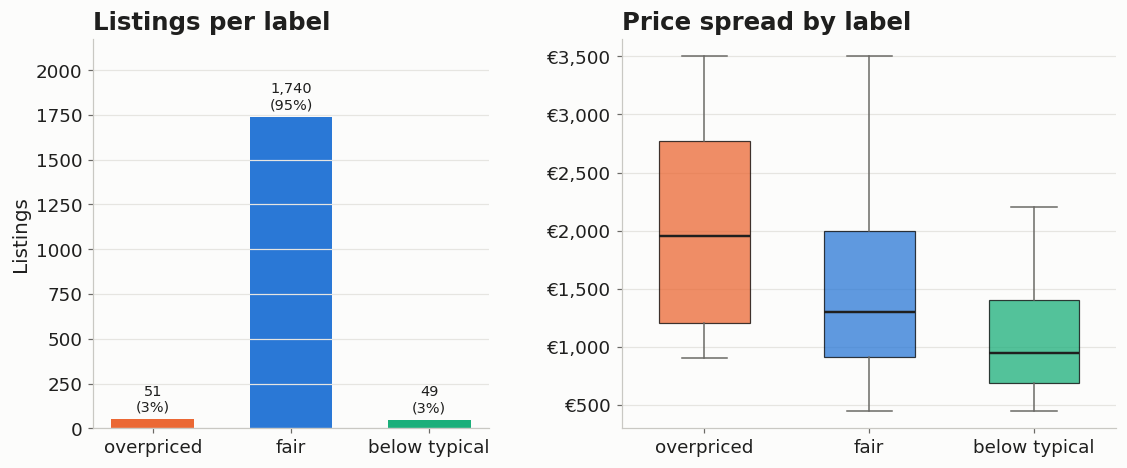

,count,median,mean
label,,,
overpriced,51,1950.0,2037.0
fair,1740,1300.0,1545.0
below_typical,49,950.0,1065.0


In [7]:
counts = labels["label"].value_counts().reindex(LABEL_ORDER)
share = counts / counts.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.25], "wspace": 0.3})

ax = axes[0]
bars = ax.bar([l.replace("_", " ") for l in LABEL_ORDER], counts.values,
              color=[LABEL_COL[l] for l in LABEL_ORDER], width=0.6)
for b, n, s in zip(bars, counts.values, share.values):
    ax.text(b.get_x() + b.get_width() / 2, n + counts.max() * 0.015, f"{n:,}\n({s:.0f}%)",
            ha="center", va="bottom", fontsize=9.5, color=PAL["ink"])
ax.set_ylim(0, counts.max() * 1.25)
ax.set_title("Listings per label", loc="left")
ax.set_ylabel("Listings")

ax = axes[1]
data = [actual[labels["label"].to_numpy() == l] for l in LABEL_ORDER]
bp = ax.boxplot(data, patch_artist=True, widths=0.55, showfliers=False,
                medianprops=dict(color=PAL["ink"], lw=1.6), whiskerprops=dict(color=PAL["muted"]),
                capprops=dict(color=PAL["muted"]), boxprops=dict(lw=0.8))
for patch, l in zip(bp["boxes"], LABEL_ORDER):
    patch.set_facecolor(LABEL_COL[l]); patch.set_alpha(0.75)
ax.set_xticks(range(1, 4), [l.replace("_", " ") for l in LABEL_ORDER])
ax.yaxis.set_major_formatter(EUR)
ax.set_title("Price spread by label", loc="left")
ax.grid(axis="y", color=PAL["grid"])
plt.tight_layout()
plt.show()

summary = (labels.assign(actual=actual)
           .groupby("label")["actual"].agg(["count", "median", "mean"])
           .reindex(LABEL_ORDER).round(0))
summary

**Reading this:** The split is 95% fair, 3% overpriced (51 flats) and 3% below typical (49 flats). Overpriced flats have a median rent of €1,950, against €1,300 for fair and €950 for below typical. The flags are spread across 41 and 35 neighbourhoods respectively, so no single area dominates. Because the labels come from the same model that predicts rent, they are not independent evidence that the flagged flats are mispriced.

## 6. Where do the overpriced listings cluster? (neighbourhoods)

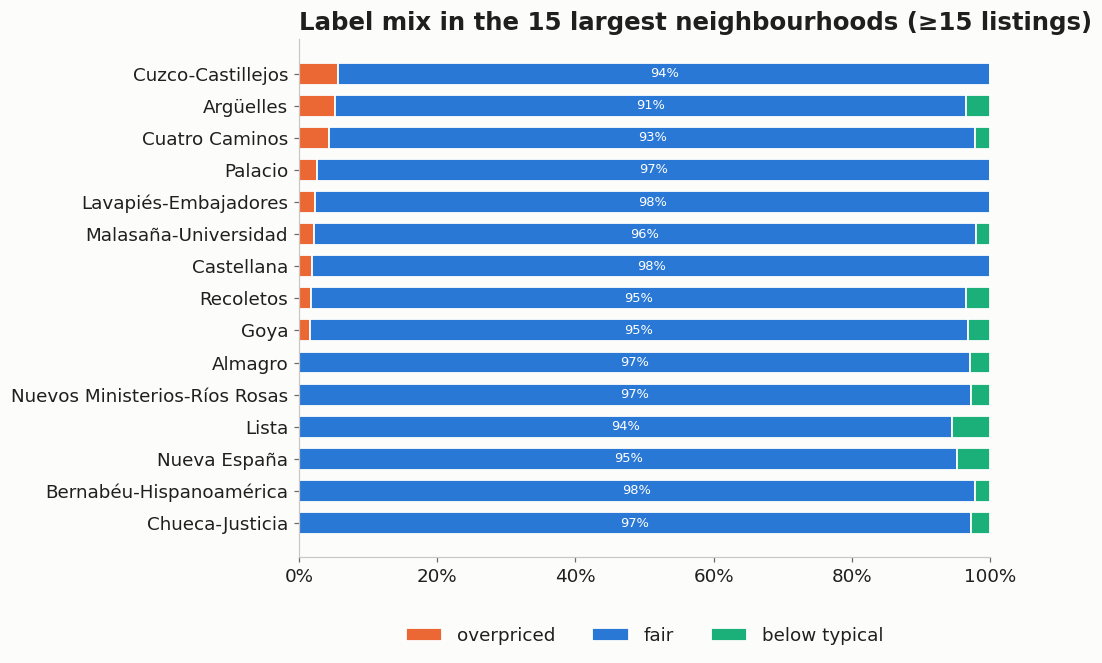

In [8]:
nb = labels.assign(neighborhood=df["Area"].to_numpy())
nb_counts = nb["neighborhood"].value_counts()
top = nb_counts[nb_counts >= 15].index[:15]
mix = (pd.crosstab(nb["neighborhood"], nb["label"], normalize="index")
         .reindex(columns=LABEL_ORDER).loc[top] * 100)
mix = mix.loc[mix["overpriced"].sort_values().index]

fig, ax = plt.subplots(figsize=(9.5, 6.2))
left = np.zeros(len(mix))
for l in LABEL_ORDER:
    ax.barh(mix.index, mix[l], left=left, color=LABEL_COL[l], height=0.68,
            label=l.replace("_", " "), edgecolor=PAL["surface"], lw=1.2)
    for i, (v, x0) in enumerate(zip(mix[l], left)):
        if v >= 9:
            ax.text(x0 + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8.5,
                    color="white" if l != "fair" else "white")
    left += mix[l].to_numpy()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(100))
ax.set_xlim(0, 100)
ax.grid(False)
ax.set_title("Label mix in the 15 largest neighbourhoods (≥15 listings)", loc="left")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout()
plt.show()

**Reading this:** With only 100 flags, the neighbourhood bars rest on very few listings. Argüelles has the most flags (5), followed by several areas with 3 each. Treat these as places to check, not as a ranking.

## 7. Does the gap depend on the flat's type and size?

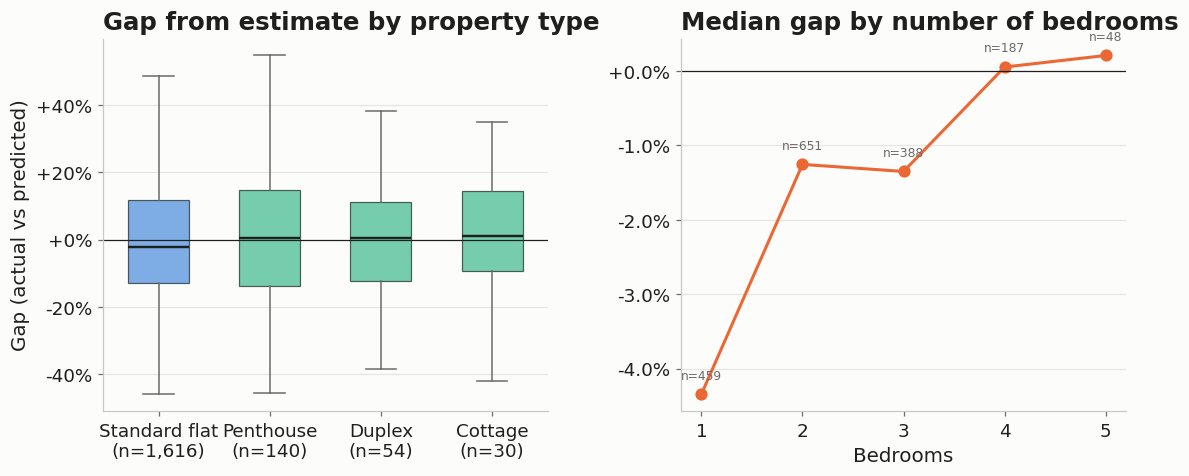

In [9]:
feat = df.copy()
feat["gap_pct"] = gap_pct
flags = ["Penthouse", "Cottage", "Duplex", "Semidetached"]
feat["type"] = np.select([feat["Penthouse"] == 1, feat["Cottage"] == 1, feat["Duplex"] == 1, feat["Semidetached"] == 1],
                         ["Penthouse", "Cottage", "Duplex", "Semidetached"], default="Standard flat")
feat["Bedrooms"] = pd.to_numeric(feat["Bedrooms"], errors="coerce")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"wspace": 0.3})

ax = axes[0]
counts = feat["type"].value_counts()
kinds = [k for k in ["Standard flat", "Penthouse", "Duplex", "Semidetached", "Cottage"] if counts.get(k, 0) >= 15]
data = [feat.loc[feat["type"] == k, "gap_pct"].clip(-60, 60) for k in kinds]
bp = ax.boxplot(data, patch_artist=True, widths=0.55, showfliers=False,
                medianprops=dict(color=PAL["ink"], lw=1.6), whiskerprops=dict(color=PAL["muted"]),
                capprops=dict(color=PAL["muted"]), boxprops=dict(lw=0.8))
for p_, k in zip(bp["boxes"], kinds):
    p_.set_facecolor(PAL["primary"] if k == "Standard flat" else PAL["teal"]); p_.set_alpha(0.6)
ax.axhline(0, color=PAL["ink"], lw=0.8)
ax.set_xticks(range(1, len(kinds) + 1), [f"{k}\n(n={counts[k]:,})" for k in kinds])
ax.yaxis.set_major_formatter(PCT)
ax.set_title("Gap from estimate by property type", loc="left")
ax.set_ylabel("Gap (actual vs predicted)")

ax = axes[1]
bed = feat[feat["Bedrooms"].between(0, 6)]
g = bed.groupby("Bedrooms")["gap_pct"].agg(["median", "count"])
g = g[g["count"] >= 20]
ax.plot(g.index, g["median"], color=PAL["accent"], marker="o", ms=7, lw=2)
for x, row in g.iterrows():
    ax.annotate(f"n={int(row['count'])}", (x, row["median"]), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=8, color=PAL["muted"])
ax.axhline(0, color=PAL["ink"], lw=0.8)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:+.1f}%"))
ax.set_xlabel("Bedrooms")
ax.set_title("Median gap by number of bedrooms", loc="left")
plt.tight_layout()
plt.show()

**Reading this:** Standard flats sit slightly below the estimate (median −2.1%), while penthouses (+0.4%), duplexes (+0.4%) and cottages (+1.2%) sit close to zero. By bedroom count, one-bedroom flats are at −4.3% and two-bedroom flats at −1.2%, while four-bedroom and larger flats are close to zero. Groups with fewer than 20 flats are left out.

## 8. What drives the predictions? (permutation importance)

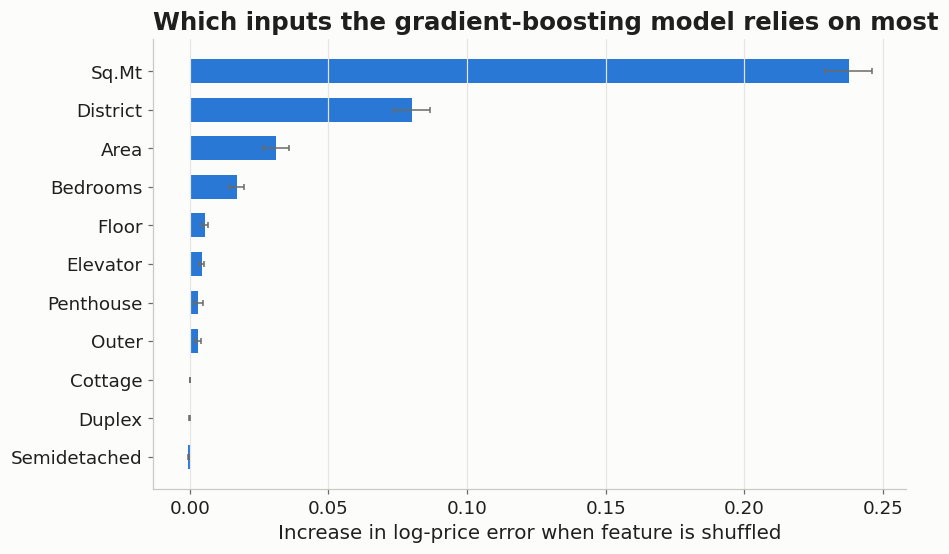

In [10]:
# Honest check: fit on 80% of listings and measure importance on the untouched 20%.
X_tr, X_te, y_tr, y_te = train_test_split(X, y_log, test_size=0.2, random_state=SEED)
gbm = make_models()["gradient_boosting"].fit(X_tr, y_tr)
perm = permutation_importance(gbm, X_te, y_te, n_repeats=10, random_state=SEED,
                              scoring="neg_mean_absolute_error")

imp = pd.DataFrame({"feature": X.columns, "mean": perm.importances_mean, "std": perm.importances_std})
imp = imp.sort_values("mean").tail(12)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.barh(imp["feature"], imp["mean"], xerr=imp["std"], color=PAL["primary"], height=0.62,
        error_kw=dict(ecolor=PAL["muted"], lw=1, capsize=2))
ax.set_xlabel("Increase in log-price error when feature is shuffled")
ax.set_title("Which inputs the gradient-boosting model relies on most", loc="left")
ax.grid(axis="x", color=PAL["grid"]); ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Reading this:** Flat size (`Sq.Mt`) is by far the most important input, about three times as influential as the next feature, district. Location comes next: district ranks above the finer neighbourhood (`Area`), likely because the 140 neighbourhoods split into many small groups. Bedrooms add a little, and floor, elevator and the property-type flags add very little. Permutation importance is measured on a held-out 20%, so these ranks are not inflated by training data.

## 9. The listings the model flags most

In [11]:
view = pd.DataFrame({
    "address": (df["Address"].fillna("") + " " + df["Number"].fillna("").astype(str)).str.strip().str.slice(0, 48).to_numpy(),
    "Area": df["Area"].to_numpy(),
    "Sq.Mt": df["Sq.Mt"].to_numpy(),
    "actual_eur": actual,
    "predicted_eur": pred.round(0),
    "gap_pct": gap_pct.round(1),
    "label": labels["label"].to_numpy(),
})
cols = ["address", "Area", "Sq.Mt", "actual_eur", "predicted_eur", "gap_pct", "label"]

def pretty(frame):
    out = frame.copy()
    out["actual_eur"] = out["actual_eur"].map("€{:,.0f}".format)
    out["predicted_eur"] = out["predicted_eur"].map("€{:,.0f}".format)
    out["gap_pct"] = out["gap_pct"].map("{:+.1f}%".format)
    return out.reset_index(drop=True)

print("Most overpriced vs the model:")
display(pretty(view.sort_values("gap_pct", ascending=False).head(10)[cols]))
print("Most underpriced vs the model:")
display(pretty(view.sort_values("gap_pct").head(10)[cols]))

Most overpriced vs the model:


,address,Area,Sq.Mt,actual_eur,predicted_eur,gap_pct,label
0,Piso en San Isidro,San Isidro,85,"€1,950",€695,+180.6%,overpriced
1,Piso en calle Genciana 29,Valdeacederas,80,"€2,750","€1,030",+166.9%,overpriced
2,Piso en LAVAPIES,Lavapiés-Embajadores,60,"€2,300",€919,+150.3%,overpriced
3,Piso en calle de Ofelia Nieto 59,Valdezarza,110,"€2,850","€1,182",+141.1%,overpriced
4,Ático en El Viso,en El Viso,90,"€2,900","€1,256",+130.9%,overpriced
5,Piso en paseo de San Francisco de Sales 15,Vallehermoso,50,"€2,160",€937,+130.6%,overpriced
6,Piso en calle de Don Ramón de la Cruz 93,Lista,47,"€2,430","€1,064",+128.5%,fair
7,Ático en Princesa 73,Argüelles,56,"€2,800","€1,226",+128.4%,overpriced
8,Piso en calle Angelita Cavero 5,San Pascual,55,"€1,800",€798,+125.7%,overpriced
9,Piso en calle del príncipe de vergara 136,Ciudad Jardín,75,"€3,150","€1,440",+118.8%,overpriced


Most underpriced vs the model:


,address,Area,Sq.Mt,actual_eur,predicted_eur,gap_pct,label
0,Piso en Princesa,Argüelles,73,"€1,000","€2,522",-60.4%,below_typical
1,Estudio en calle de Martín de los Heros 53,Argüelles,60,€450,"€1,030",-56.3%,below_typical
2,Estudio en avenida Real de Pinto 5,San Andrés,200,€900,"€2,046",-56.0%,below_typical
3,Piso en San Hermenegildo,Chueca-Justicia,50,€700,"€1,296",-46.0%,below_typical
4,Ático en calle san roque 12,Malasaña-Universidad,50,€730,"€1,343",-45.6%,below_typical
5,Piso en calle del Doctor Esquerdo,Goya,85,€925,"€1,685",-45.1%,fair
6,Piso en calle Viriato 38,Trafalgar,110,"€1,200","€2,155",-44.3%,fair
7,Piso en Almagro,Almagro,98,"€1,200","€2,153",-44.3%,below_typical
8,Ático en calle Martires Concepcionistas 16,Lista,200,"€1,600","€2,863",-44.1%,below_typical
9,Piso en Goya,Goya,110,"€1,500","€2,673",-43.9%,below_typical


**Reading this:** Use these tables to spot-check the extremes. Open the addresses and confirm each record is right before acting on a flag.

## 10. Caveats

- **Relative, not true, rents.** Labels say how a flat compares with similar flats in this listing dataset (1,840 flats, after removing 44 duplicates and the 205 most expensive rents). They are not a measure of market value.
- **Circular labels.** The labels come from the same model that predicts rent. The honest test of the model is the out-of-fold euro error in section 2.
- **Interval width varies; flags are few.** Each interval scales with the flat's learned uncertainty: half-widths run from about 15% to 257% of the predicted rent (median 49%), roughly €270 in the cheapest quartile and €1,000 in the most expensive. Coverage was 92.9% overall and between 90% and 96% in each rent quartile, on 368 held-out flats from a single split, so the exact flag counts are uncertain. Only 100 flats (5.4%) are flagged.
- **Price range.** The model is trained on rents from €450 to €3,500. It is not designed for luxury flats above that range.
- **Suspect values.** `Sq.Mt` can be extreme (the raw file goes up to 1,250 m²). `Floor` values outside −1 to 30 are set to missing. Check both against the source listings.
- **Missing values.** `Bedrooms`, `Floor`, `Outer` and `Elevator` have a few percent missing, which are median-imputed with an indicator column. `Number` is mostly missing and is not used.
- **Small groups.** Many neighbourhoods have fewer than 20 flats, so their shares are unstable.